In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.differentiate import jacobian

In [32]:
##### calibration
std_fs = 0.15 * 0.05 / 100
std_u_temp = 0.08 / 1000
std_U = std_fs + std_u_temp

# at lab-pressure and temperature
U_lab = 0.15 # measurement
p_lab = 1 # measurement

std_p_lab = 0.001 # estimation

# low-pressure (# evacuate pump (7-10min))
U_2 = 0.000015 # measurement
p_2 = 0.0001 # +- 0.0001 bar

std_p_2 = 0.0001

x = np.array([U_lab, U_2])
y = np.array([p_lab, p_2])

In [33]:
def pr (prr_u, prr_pl, prr_p2, prr_ul, prr_u2):
    prr_c = (prr_pl - prr_p2) / (prr_ul - prr_u2)
    prr_p0 = prr_pl - prr_ul * prr_c
    return prr_p0 + prr_u * prr_c

def pr_U (prr_U, prr_p_0, prr_C):
    return prr_p_0 + prr_U * prr_C

C = 6.666666666666666 +- 0.01182499191645656
p_0 = 1.1102230246251565e-16 +- 0.0010382646032456716


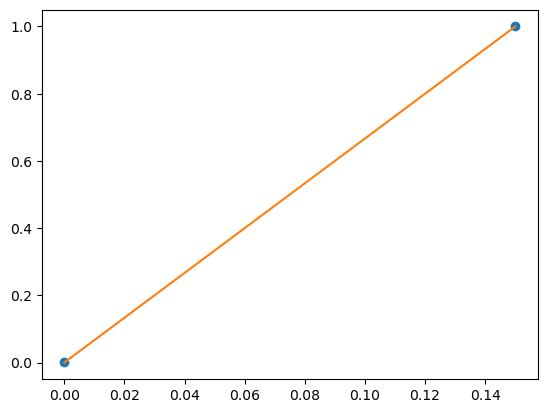

In [34]:
C = (p_lab - p_2) / (U_lab - U_2)
p_0 = p_lab - U_lab * C # = p_lab - (p_lab - p_2) / (1 - U_2 / U_lab)


Cdelp_lab = 1 / (U_lab - U_2)
Cdelp_2 = (-1) / (U_lab - U_2)
CdelU_lab = (-1) * (p_lab - p_2) / (U_lab - U_2)**2
CdelU_2 = (p_lab - p_2) / (U_lab - U_2)**2
std_C = np.sqrt((Cdelp_lab * std_p_lab)**2
                + (Cdelp_2 * std_p_2)**2
                + (CdelU_lab * std_U)**2
                + (CdelU_2 * std_U)**2)

p_0delp_lab = 1 - 1 / (1 - U_2 / U_lab)
p_0delp_2 = 1 / (1 - U_2 / U_lab)
p_0delU_2 = (p_lab - p_2) / (1 - U_2 / U_lab)**2 / U_lab * (-1)
p_0delU_lab = (p_lab - p_2) / (1 - U_2 / U_lab)**2 * U_2 / U_lab**2
std_p_0 = np.sqrt((p_0delp_lab * std_p_lab)**2
                + (p_0delp_2 * std_p_2)**2
                + (p_0delU_2 * std_U)**2
                + (p_0delU_lab * std_U)**2)

print('C =', C, '+-', std_C)
print('p_0 =', p_0, '+-', std_p_0)

plt.plot(x, y, marker='o', linestyle='')
plt.plot(np.linspace(np.min(x), np.max(x), 20), pr_U(np.linspace(np.min(x), np.max(x), 20), p_0, C))

In [35]:
##### absolute zero
# evacuate pump (7-10min (maybe already done))
# fill with helium for at least two minutes
# repeat procedure once

In [36]:
# boiling water (close opening after heating)
U_k = 0.15 # measurment
t_k = 100 # table relation with pressure

p_k = pr_U(U_k, p_0, C) # = p_lab - (p_lab - p_2) / (1 - U_2 / U_lab) + U_k * (p_lab - p_2) / (U_lab - U_2)

std_t_k = 1 # estimation

p_kdelp_lab = 1 - 1 / (1 - U_2 / U_lab) + U_k / (U_lab - U_2)
p_kdelp_2 = 1 / (1 - U_2 / U_lab) - U_k / (U_lab - U_2)
p_kdelU_2 = (-1) * (p_lab - p_2) / (1 - U_2 / U_lab)**2 / U_lab + U_k * (p_lab - p_2) / (U_lab - U_2)**2
p_kdelU_lab = (p_lab - p_2) / (1 - U_2 / U_lab)**2 * U_2 / U_lab**2 - U_k * (p_lab - p_2) / (U_lab - U_2)**2
p_kdelU_k = (p_lab - p_2) / (U_lab - U_2)
std_p_k = np.sqrt((p_kdelp_lab * std_p_lab)**2
                + (p_kdelp_2 * std_p_2)**2
                + (p_kdelU_2 * std_U)**2
                + (p_kdelU_lab * std_U)**2
                + (p_kdelU_k * std_U)**2)

print(p_k)
print(std_p_k)

1.0
0.0017707499980391232


In [37]:
# ice water
# make cold ice water wait ca 2min
U_e = 0.1098 # measurment
t_e = 0 # temperature ice-water

p_e = pr_U(U_e, p_0, C)

std_t_e = 1 # estimation

p_edelp_lab = 1 - 1 / (1 - U_2 / U_lab) + U_e / (U_lab - U_2)
p_edelp_2 = 1 / (1 - U_2 / U_lab) - U_e / (U_lab - U_2)
p_edelU_2 = (-1) * (p_lab - p_2) / (1 - U_2 / U_lab)**2 / U_lab + U_e * (p_lab - p_2) / (U_lab - U_2)**2
p_edelU_lab = (p_lab - p_2) / (1 - U_2 / U_lab)**2 * U_2 / U_lab**2 - U_e * (p_lab - p_2) / (U_lab - U_2)**2
p_edelU_e = (p_lab - p_2) / (U_lab - U_2)
std_p_e = np.sqrt((p_edelp_lab * std_p_lab)**2
                + (p_edelp_2 * std_p_2)**2
                + (p_edelU_2 * std_U)**2
                + (p_edelU_lab * std_U)**2
                + (p_edelU_e * std_U)**2)

print(p_e)
print(std_p_e)

0.732
0.0015010287795278084


In [38]:
##### calculations:
t_0_approx = (-1) * p_e * t_k / (p_k - p_e)

t_0_approxdelp_e = (-1) * t_k / (p_k / p_e - 1)**2 * p_k / p_e**2
t_0_approxdelt_k = (-1) * p_e / (p_k - p_e)
t_0_approxdelp_k = p_e * t_k / (p_k - p_e)**2
std_t_0_approx = np.sqrt((t_0_approxdelp_e * std_p_e)**2
                        + (t_0_approxdelt_k * std_t_k)**2
                        + (t_0_approxdelp_k * std_p_k)**2)



print(t_0_approx)
print(std_t_0_approx)

-273.13432835820896
3.883895457332804


In [39]:
epsilon = 10**(-3)
gamma = 10**(-5)

def ft0(data):
    pl = data[0]
    p2 = data[1]
    ul = data[2]
    u2 = data[3]

    uk = data[4]
    ue = data[5]
    pk = pr(uk, pl, p2, ul, u2)
    pe = pr(ue, pl, p2, ul, u2)

    tk = data[6]
    te = data[7]
    tl = data[8]

    aa = (1 + epsilon) * pe - (1 + epsilon + gamma * tk) * pk
    bb = epsilon * (pk - pe) * (te + tk) + (1 + gamma * tk) * pk * (te + tl) - pe * (tl + tk)
    cc = pe * tl * tk + epsilon * (pe - pk) * te * tk - (1 + gamma * tk) * pk * te * tl

    t_00 = ((-1) * bb + np.sqrt(bb**2 - 4 * aa * cc)) / (2 * aa)
    return t_00

def t_00 (data):
    pk = data[0]
    pe = data[1]
    tk = data[2]
    te = data[3]
    tl = data[4]

    aa = (1 + epsilon) * pe - (1 + epsilon + gamma * tk) * pk
    bb = epsilon * (pk - pe) * (te + tk) + (1 + gamma * tk) * pk * (te + tl) - pe * (tl + tk)
    cc = pe * tl * tk + epsilon * (pe - pk) * te * tk - (1 + gamma * tk) * pk * te * tl

    t_00 = ((-1) * bb + np.sqrt(bb**2 - 4 * aa * cc)) / (2 * aa)
    return t_00


In [40]:
t_lab = 23 #measurment?

std_t_lab = 1

z = np.array([p_k, p_e, t_k, t_e, t_lab])
std_z = np.array([std_p_k, std_p_e, std_t_k, std_t_e, std_t_lab])

zzz = np.array([p_lab, p_2, U_lab, U_2, U_k, U_e, t_k, t_e, t_lab])
std_zzz = np.array([std_p_lab, std_p_2, std_U, std_U, std_U, std_U, std_t_k, std_t_e, std_t_lab])

t_0 = t_00(z)

jac = jacobian(t_00, z).df
std_t_0 = np.sqrt(jac**2 @ std_z.transpose()**2)

jaccc = jacobian(ft0, zzz).df
std_t_000 = np.sqrt(jaccc**2 @ std_zzz.transpose()**2)


print('t_0 =', t_0, '+-', std_t_0)
print(ft0(zzz), '+-', std_t_000)

t_0 = -271.7774638021861 +- 5.354441309961325
-271.7774638021861 +- 4.943510479805984


In [41]:
##### liquid nitrogen
U_LN2 = 0.031 # measurement
p_LN2 = pr_U(U_LN2, p_0, C)

p_LN2delp_lab = 1 - 1 / (1 - U_2 / U_lab) + U_LN2 / (U_lab - U_2)
p_LN2delp_2 = 1 / (1 - U_2 / U_lab) - U_LN2 / (U_lab - U_2)
p_LN2delU_2 = (-1) * (p_lab - p_2) / (1 - U_2 / U_lab)**2 / U_lab + U_LN2 * (p_lab - p_2) / (U_lab - U_2)**2
p_LN2delU_lab = (p_lab - p_2) / (1 - U_2 / U_lab)**2 * U_2 / U_lab**2 - U_LN2 * (p_lab - p_2) / (U_lab - U_2)**2
p_LN2delU_LN2 = (p_lab - p_2) / (U_lab - U_2)
std_p_LN2 = np.sqrt((p_LN2delp_lab * std_p_lab)**2
                + (p_LN2delp_2 * std_p_2)**2
                + (p_LN2delU_2 * std_U)**2
                + (p_LN2delU_lab * std_U)**2
                + (p_LN2delU_LN2 * std_U)**2)


print(p_LN2, '+-', std_p_LN2)

0.20666666666666675 +- 0.0013544342489199836


In [42]:
t_LN2_approx = (1 - p_LN2 / p_e) * t_0

std_t_LN2_approx = np.sqrt(((t_0) / p_e * (-1) * std_p_LN2)**2
                        + (p_LN2 * t_0 / p_e**2 * std_p_e)**2
                        + ((1 - p_LN2 / p_e) * std_t_0)**2)

print(t_LN2_approx, '+-', std_t_LN2_approx)

-195.04612156295318 +- 3.8786711760209873


In [43]:
def ft_ln2 (data):
    pl = data[0]
    p2 = data[1]
    ul = data[2]
    u2 = data[3]

    uk = data[4]
    ue = data[5]
    uln2 = data[6]

    pk = pr(uk, pl, p2, ul, u2)
    pe = pr(ue, pl, p2, ul, u2)
    pln2 = pr(uln2, pl, p2, ul, u2)

    tk = data[7]
    te = data[8]
    tl = data[9]

    idk = np.array([pl, p2, ul, u2, uk, ue, tk, te, tl])
    t0 = ft0(idk)
    
    AAAAA = pe / (te - t0) + epsilon * (pe - pln2) / (tl - t0)

    return (AAAAA * t0 + pln2) / (AAAAA - gamma * pln2)

def t_LN22 (data):
    pe = data[0]
    pk = data[1]
    pln2 = data[2]
    te = data[3]
    tk = data[4]
    tl = data[5]

    idk = np.array([pk, pe, tk, te, tl])
    t0 = t_00(idk)
    
    AAAAA = pe / (te - t0) + epsilon * (pe - pln2) / (tl - t0)

    return (AAAAA * t0 + pln2) / (AAAAA - gamma * pln2)

In [44]:
zz = np.array([p_e, p_k, p_LN2, t_e, t_k, t_lab])
std_zz = np.array([std_p_e, std_p_k, std_p_LN2, std_t_e, std_t_k, std_t_lab])

zzzz = np.array([p_lab, p_2, U_lab, U_2, U_k, U_e, U_LN2, t_k, t_e, t_lab])
std_zzzz = np.array([std_p_lab, std_p_2, std_U, std_U, std_U, std_U, std_U, std_t_k, std_t_e, std_t_lab])

t_LN2 = t_LN22(zz)

jacc = jacobian(t_LN22, zz).df
std_t_LN2 = np.sqrt(jacc**2 @ std_zz.transpose()**2)

jacccc = jacobian(ft_ln2, zzzz).df
std_t_LN222 = np.sqrt(jacccc**2 @ std_zzzz.transpose()**2)

print(t_LN2, '+-', std_t_LN2)
print(ft_ln2(zzzz), '+-', std_t_LN222)

#3.810765165962369

-195.24657526002048 +- 4.141339307005659
-195.24657526002048 +- 3.810765165962369
